Goal: to check if distances between two sets of points evenly mixed across a distance have a smaller average inter-point distance than points separated on two sides of the same plane

@Lisa: I think only the second part of this notebook is relevant

Conclusion: this is the case for normally-distributed point sets but not uniformly distributed

In [1]:
from scipy.stats import uniform
import numpy as np
import pandas as pd
from sklearn.metrics import pairwise_distances
import seaborn as sns

In [2]:
import matplotlib.pyplot as plt

In [3]:
%load_ext nb_black

<IPython.core.display.Javascript object>

In [45]:
n_points = 10000
n_dims = 2
distr = "gaussian"  # either gaussian or uniform

<IPython.core.display.Javascript object>

Generate two mixing sets of points; scattered out from -1 to 1

In [46]:
if distr == "uniform":
    set_1 = np.random.uniform(low=-1, high=1, size=(n_points, n_dims))
    set_2 = np.random.uniform(low=-1, high=1, size=(n_points, n_dims))
elif distr == "gaussian":
    mean_1_2 = 0
    stdev = 1
    set_1 = np.random.normal(loc=mean_1_2, scale=stdev, size=(n_points, n_dims))
    set_2 = np.random.normal(loc=mean_1_2, scale=stdev, size=(n_points, n_dims))
else:
    raise ValueError(
        "The variable 'distr' should be set either to 'gaussian' or 'uniform'"
    )

<IPython.core.display.Javascript object>

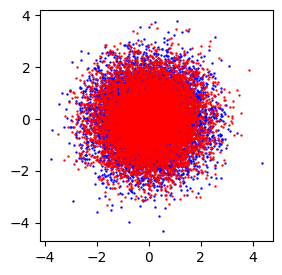

<IPython.core.display.Javascript object>

In [47]:
fig, ax = plt.subplots(figsize=(3, 3))
dotsize=0.5
plt.scatter(x=set_1[:, 0], y=set_1[:, 1], color="blue",s=dotsize)
plt.scatter(x=set_2[:, 0], y=set_2[:, 1], color="red",s=dotsize)
plt.show()

calculate average pairwise distances:

In [48]:
dists_1_2 = pairwise_distances(set_1, set_2).flatten()

<IPython.core.display.Javascript object>

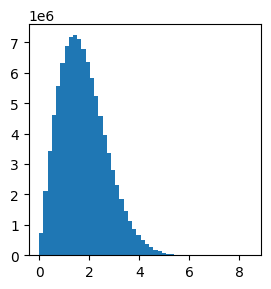

<IPython.core.display.Javascript object>

In [49]:
plt.figure(figsize=(3, 3))
plt.hist(dists_1_2, bins=50)
plt.show()

In [50]:
print(
    f"Mean pairwise distance between points (distribution: {distr}) in set 1 and set 2:",
    np.round(np.mean(dists_1_2), 2),
)

Mean pairwise distance between points (distribution: gaussian) in set 1 and set 2: 1.77


<IPython.core.display.Javascript object>

Split distribution in four and see if mean inter-sample cell-to-cell distances are indeed larger now

In [51]:
set_q1 = np.concatenate(
    (
        set_1[(set_1[:, 0] < 0) & (set_1[:, 1] > 0)],
        set_2[(set_2[:, 0] < 0) & (set_2[:, 1] > 0)],
    )
)
set_q2 = np.concatenate(
    (
        set_1[(set_1[:, 0] > 0) & (set_1[:, 1] > 0)],
        set_2[(set_2[:, 0] > 0) & (set_2[:, 1] > 0)],
    )
)
set_q4 = np.concatenate(
    (
        set_1[(set_1[:, 0] < 0) & (set_1[:, 1] < 0)],
        set_2[(set_2[:, 0] < 0) & (set_2[:, 1] < 0)],
    )
)
set_q3 = np.concatenate(
    (
        set_1[(set_1[:, 0] > 0) & (set_1[:, 1] < 0)],
        set_2[(set_2[:, 0] > 0) & (set_2[:, 1] < 0)],
    )
)

<IPython.core.display.Javascript object>

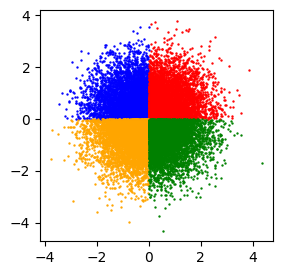

<IPython.core.display.Javascript object>

In [52]:
fig, ax = plt.subplots(figsize=(3, 3))
plt.scatter(x=set_q1[:, 0], y=set_q1[:, 1], color="blue", s=dotsize)
plt.scatter(x=set_q2[:, 0], y=set_q2[:, 1], color="red", s=dotsize)
plt.scatter(x=set_q4[:, 0], y=set_q4[:, 1], color="orange", s=dotsize)
plt.scatter(x=set_q3[:, 0], y=set_q3[:, 1], color="green", s=dotsize)
plt.show()

calculate average pairwise distances

In [53]:
dist_q1_q2 = pairwise_distances(set_q1, set_q2).flatten()
dist_q1_q3 = pairwise_distances(set_q1, set_q3).flatten()
dist_q1_q4 = pairwise_distances(set_q1, set_q4).flatten()
dist_q2_q3 = pairwise_distances(set_q2, set_q3).flatten()
dist_q2_q4 = pairwise_distances(set_q2, set_q4).flatten()
dist_q3_q4 = pairwise_distances(set_q3, set_q4).flatten()

<IPython.core.display.Javascript object>

calculate mean inter-sample distance:

In [54]:
np.mean([np.mean(x) for x in [dist_q1_q2, dist_q1_q3, dist_q1_q4, dist_q2_q3, dist_q2_q4,dist_q3_q4]])

2.011801008686685

<IPython.core.display.Javascript object>

### Note: I think the below is not comparable as I generate completely new Gaussians with different distributions, so likely ignore

Generate two separated sets of points, from -1 to 0 and from 0 to 1 on the x-axis

In [15]:
# if distr == "uniform":
#     set_3 = np.random.uniform(low=(-1, -1), high=(0, 1), size=(n_points, n_dims))
#     set_4 = np.random.uniform(low=(0, -1), high=(1, 1), size=(n_points, n_dims))
# elif distr == "gaussian":
#     mean_3 = (-1, 0)
#     mean_4 = (1, 0)
#     set_3 = np.random.normal(loc=mean_3, scale=stdev, size=(n_points, n_dims))
#     set_4 = np.random.normal(loc=mean_4, scale=stdev, size=(n_points, n_dims))

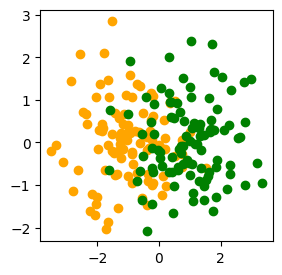

In [16]:
# fig, ax = plt.subplots(figsize=(3, 3))
# plt.scatter(x=set_3[:, 0], y=set_3[:, 1], color="orange")
# plt.scatter(x=set_4[:, 0], y=set_4[:, 1], color="green")
# plt.show()

In [17]:
# dists_3_4 = pairwise_distances(set_3, set_4).flatten()

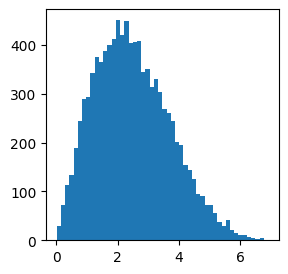

In [18]:
# plt.figure(figsize=(3, 3))
# plt.hist(dists_3_4, bins=50)
# plt.show()

In [19]:
# print(
#     f"Mean pairwise distance between points (distribution: {distr}) in set 3 and set 4:",
#     np.round(np.mean(dists_3_4)),
# )

Mean pairwise distance between points (distribution: gaussian) in set 3 and set 4: 2.0


### Part 2: 3 ref samples, 1 query

To show that if query is not mixing with "total reference", this is only a problem if reference is mixing well within itself. If reference samples themselves are not mixing either, then query is not an "outlier" and is actually mixing as well as reference with itself (see difference between "mixing" and "non_mixing" for ref_mixing variable.

In [97]:
ref_mixing = "not_mixing"  # either mixing or not_mixing or partly_mixing

<IPython.core.display.Javascript object>

In [98]:
# reference
stdev_q = 0.2
if ref_mixing == "mixing":
    mean_5 = mean_6 = mean_7 = (0, 0)
    stdev_ref = 0.35
elif ref_mixing == "not_mixing":
    mean_5 = (0, 0.5)
    mean_6 = (0, -0.5)
    mean_7 = (0.5, 0)
    stdev_ref = stdev_q
elif (
    ref_mixing == "partly_mixing"
):  # I think this only really works with a large number of reference samples
    mean_5 = (0, 0)
    mean_6 = (0, 0)
    mean_7 = (0, 0.5)
    stdev_ref = stdev_q
else:
    raise ValueError(
        "ref_mixing should be set either to 'mixing', 'partly_mixing' or 'not_mixing'"
    )
set_5 = np.random.normal(loc=mean_5, scale=stdev_ref, size=(n_points, n_dims))
set_6 = np.random.normal(loc=mean_6, scale=stdev_ref, size=(n_points, n_dims))
set_7 = np.random.normal(loc=mean_7, scale=stdev_ref, size=(n_points, n_dims))
# query
mean_8 = (-0.5, 0)
set_8 = np.random.normal(loc=mean_8, scale=stdev_q, size=(n_points, n_dims))

<IPython.core.display.Javascript object>

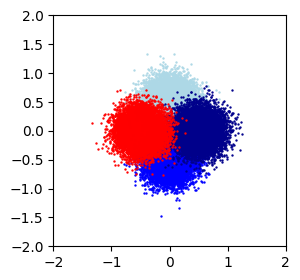

<IPython.core.display.Javascript object>

In [99]:
fig, ax = plt.subplots(figsize=(3, 3))
plt.scatter(x=set_5[:, 0], y=set_5[:, 1], color="lightblue", s=dotsize)
plt.scatter(x=set_6[:, 0], y=set_6[:, 1], color="blue", s=dotsize)
plt.scatter(x=set_7[:, 0], y=set_7[:, 1], color="darkblue", s=dotsize)
plt.scatter(x=set_8[:, 0], y=set_8[:, 1], color="red", s=dotsize)
plt.xlim((-2, 2))
plt.ylim((-2, 2))
plt.show()

calculate intersample distances reference samples:

In [100]:
dists_to_ref = pd.DataFrame(
    index=[5, 6, 7, 8],
    data={"dist_to_ref": 4 * [np.nan], "ref_or_q": ["ref", "ref", "ref", "q"]},
)

<IPython.core.display.Javascript object>

In [101]:
dist_5_6 = np.mean(pairwise_distances(set_5, set_6).flatten())
dist_5_7 = np.mean(pairwise_distances(set_5, set_7).flatten())
dist_6_7 = np.mean(pairwise_distances(set_6, set_7).flatten())
dists_to_ref.loc[5, "dist_to_ref"] = np.mean([dist_5_6, dist_5_7])
dists_to_ref.loc[6, "dist_to_ref"] = np.mean([dist_5_6, dist_6_7])
dists_to_ref.loc[7, "dist_to_ref"] = np.mean([dist_5_7, dist_6_7])

<IPython.core.display.Javascript object>

In [102]:
dist_5_8 = np.mean(pairwise_distances(set_5, set_8).flatten())
dist_6_8 = np.mean(pairwise_distances(set_6, set_8).flatten())
dist_7_8 = np.mean(pairwise_distances(set_7, set_8).flatten())
dists_to_ref.loc[8, "dist_to_ref"] = np.mean([dist_5_8, dist_6_8, dist_7_8])

<IPython.core.display.Javascript object>

In [103]:
dists_to_ref

,dist_to_ref,ref_or_q
5,0.904842,ref
6,0.906307,ref
7,0.768002,ref
8,0.858640,q


<IPython.core.display.Javascript object>

/var/folders/nq/rgzpdy4j7ws929rv11gf95q40000gn/T/ipykernel_5057/4119276263.py:23: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  leg = plt.legend(loc=(1.01, 0.4), frameon=False, title="")


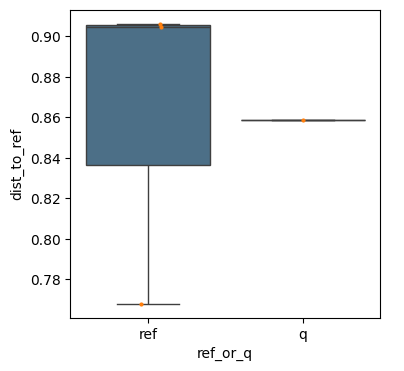

<IPython.core.display.Javascript object>

In [104]:
fig = plt.figure(figsize=(4, 4))
ax = fig.add_subplot()
sns.boxplot(
    dists_to_ref,
    x="ref_or_q",
    y="dist_to_ref",
    # hue=hue,
    ax=ax,
    saturation=0.4,
    # palette=palette,
)
sns.stripplot(
    dists_to_ref,
    x="ref_or_q",
    y="dist_to_ref",
    # hue=hue,
    ax=ax,
    # palette=palette,
    dodge=True,
    size=3,
    # palette="dark:black",
)
leg = plt.legend(loc=(1.01, 0.4), frameon=False, title="")
leg._legend_box.align = "left"

In [105]:
dists_to_ref

,dist_to_ref,ref_or_q
5,0.904842,ref
6,0.906307,ref
7,0.768002,ref
8,0.858640,q


<IPython.core.display.Javascript object>

In [106]:
dists_to_ref.groupby("ref_or_q").median()

,dist_to_ref
ref_or_q,
q,0.858640
ref,0.904842


<IPython.core.display.Javascript object>